# 13. What drives what: `granger_causality` and `fevd`

Notebook 12 asked what helps predict what from the raw data, before any fit. This notebook asks the same question of the fitted posterior. It walks through two post-fit methods:

| Method | Returns | Question |
|---|---|---|
| `model.granger_causality()` | `CausalityResult` | Which links does the posterior support, and how strongly? |
| `model.fevd(steps)` | `xr.DataArray` | Of the uncertainty in each forecast, what share comes from each series' shocks? |

Both are read straight from the posterior draws, so they need no extra sampling. The data is the simulated brand system from notebook 11, so every verdict can be checked against the truth.

In [1]:
from __future__ import annotations

import warnings

import matplotlib.pyplot as plt
import pandas as pd

from bayesian_vecm import BayesianVECM, CausalityResult, simulate_brand_data
from bayesian_vecm._causality import evidence_against_zero

warnings.filterwarnings("ignore", category=FutureWarning)

# Set FAST_SAMPLING = False for publication-quality posteriors.
FAST_SAMPLING = True
DRAWS, TUNE, CHAINS = (500, 500, 2) if FAST_SAMPLING else (1000, 1000, 4)

## 1. Fit the brand model

The specification matches the truth: one lag of differences, rank 2 and an unrestricted constant. All five drivers enter as `exog`.

In [2]:
data = simulate_brand_data()
truth = data.truth
names = list(data.endog.columns)

model = BayesianVECM(k_ar_diff=1, coint_rank=2, deterministic="co")
model.fit(
    data.endog,
    exog=data.exog,
    draws=DRAWS,
    tune=TUNE,
    chains=CHAINS,
    random_seed=42,
    progressbar=False,
)
print("divergences:", int(model.idata.sample_stats["diverging"].sum()))

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


divergences: 0


## 2. `granger_causality`: four tables of evidence

### What it does

`granger_causality` returns a `CausalityResult` with four tables. Each asks whether one block of parameters is zero:

| Table | Quantity | Question |
|---|---|---|
| `short_run` | the block of $\Gamma$ linking X to Y, across all lags | Does lagged growth in X help predict growth in Y? |
| `long_run` | one entry of $\Pi = \alpha \beta^\top$ | Does the level of X pull on Y? |
| `weak_exogeneity` | the variable's whole row of $\alpha$ | Does the variable adjust to the long-run relations at all? |
| `exog` | the driver's entries of $B$ | Does the driver help predict Y? |

The long-run table uses $\Pi$, not $\alpha$. $\Pi$ does not depend on how $\beta$ is normalised (notebook 03 §7), so its entries have a fixed meaning.

### Why the model needs it

A sampler gives a posterior over every coefficient. A practitioner wants the links. These tables turn one into the other, with a single number per link.

In [3]:
causality = model.granger_causality()
assert isinstance(causality, CausalityResult)
print(causality)

What helps predict what
  evidence threshold = 0.95   Gamma prior = Normal

Short run: lagged growth in the cause (Gamma)
  cause -> effect                                evidence     mean  verdict
  ----------------------------------------------------------------------------------
  organic_sales -> brand_awareness                   0.08   -0.004  no clear evidence
  organic_sales -> brand_consideration               0.43   -0.022  no clear evidence
  brand_awareness -> organic_sales                   0.27    0.031  no clear evidence
  brand_awareness -> brand_consideration             1.00    0.249  helps predict
  brand_consideration -> organic_sales               1.00    0.535  helps predict
  brand_consideration -> brand_awareness             0.49    0.038  no clear evidence

Long run: level of the cause (Pi = alpha beta')
  cause -> effect                                evidence     mean  verdict
  ----------------------------------------------------------------------------------

### The evidence measure

Each row carries one number between 0 and 1: the highest credible level at which zero lies outside the posterior region. A value near 1 means the posterior sits far from zero. The default threshold for a link is 0.95.

For one coefficient with a symmetric posterior it equals $1 - 2 \min(P(>0), P(<0))$. The check below confirms that on the awareness to sales entry of $\Gamma$, which has no true effect. For a block of several coefficients the region is the ellipsoid given by the posterior mean and covariance.

In [4]:
draws = model.idata.posterior["Gamma"].values[:, :, 0, 1].ravel()  # awareness -> sales
p_pos = (draws > 0).mean()
print(f"evidence_against_zero:      {evidence_against_zero(draws[:, None]):.3f}")
print(f"1 - 2 min(P(>0), P(<0)):    {1 - 2 * min(p_pos, 1 - p_pos):.3f}")

evidence_against_zero:      0.265
1 - 2 min(P(>0), P(<0)):    0.274


### Checking it against the truth

The tables below put the posterior verdict next to the true parameter. A link is true when its parameter is not zero.

In [5]:
idx = {n: i for i, n in enumerate(names)}
pi_true = truth.alpha @ truth.beta.T


def compare(table, true_value):
    out = table[["cause", "effect", "evidence", "mean"]].copy()
    out["truth"] = [true_value(r.cause, r.effect) for r in table.itertuples()]
    out["found"] = out["evidence"] >= causality.threshold
    return out.round(3)


print("Short run (Gamma)")
print(compare(causality.short_run, lambda c, e: truth.gamma[idx[e], idx[c]]).to_string(index=False))
print()
print("Long run (Pi)")
print(compare(causality.long_run, lambda c, e: pi_true[idx[e], idx[c]]).to_string(index=False))

Short run (Gamma)
              cause              effect  evidence   mean  truth  found
      organic_sales     brand_awareness     0.082 -0.004   0.00  False
      organic_sales brand_consideration     0.433 -0.022   0.00  False
    brand_awareness       organic_sales     0.265  0.031   0.00  False
    brand_awareness brand_consideration     1.000  0.249   0.25   True
brand_consideration       organic_sales     1.000  0.535   0.40   True
brand_consideration     brand_awareness     0.489  0.038   0.00  False

Long run (Pi)
              cause              effect  evidence   mean  truth  found
      organic_sales     brand_awareness     0.007 -0.000   0.00  False
      organic_sales brand_consideration     0.336  0.013   0.00  False
    brand_awareness       organic_sales     0.129 -0.005   0.00  False
    brand_awareness brand_consideration     1.000  0.184   0.18   True
brand_consideration       organic_sales     1.000  0.306   0.30   True
brand_consideration     brand_awareness     

- **Short run:** the two true links (awareness to consideration, consideration to sales) are found with evidence 1.00. The four absent ones are not. The consideration to sales mean (0.53) sits above the truth (0.40), at the edge of its 89% interval.
- **Long run:** the same two pairs. Consideration pulls on sales and awareness pulls on consideration. The means sit close to the true $\Pi$ entries.
- **Weak exogeneity:** awareness is reported as weakly exogenous (evidence 0.76), which matches its zero row of $\alpha$. Sales and consideration adjust.

The `exog` table finds all five true driver effects. The closest false positive is spend to consideration, at 0.88.

In [6]:
exog_idx = {n: j for j, n in enumerate(data.exog.columns)}
print("Exogenous drivers (B)")
print(compare(causality.exog, lambda c, e: truth.b[idx[e], exog_idx[c]]).to_string(index=False))

Exogenous drivers (B)
              cause              effect  evidence   mean  truth  found
        brand_spend       organic_sales     0.108  0.001  0.000  False
        brand_spend     brand_awareness     1.000  0.017  0.018   True
        brand_spend brand_consideration     0.883 -0.004  0.000  False
           pr_reach       organic_sales     0.288  0.001  0.000  False
           pr_reach     brand_awareness     1.000  0.013  0.012   True
           pr_reach brand_consideration     0.749  0.003  0.000  False
  sponsorship_reach       organic_sales     0.296 -0.001  0.000  False
  sponsorship_reach     brand_awareness     0.984  0.006  0.006   True
  sponsorship_reach brand_consideration     0.260  0.001  0.000  False
      interest_rate       organic_sales     0.724  0.004  0.000  False
      interest_rate     brand_awareness     0.506 -0.001  0.000  False
      interest_rate brand_consideration     1.000 -0.020 -0.020   True
consumer_confidence       organic_sales     0.734 -0.00

Two limits apply to every table:

- They are statements about prediction, not cause. "X helps predict Y" is as far as the short-run table goes.
- A shrinkage prior on $\Gamma$ pulls coefficients towards zero, so the short-run evidence depends on it. `causality.gamma_prior` records which prior was used.

## 3. `fevd`: where the forecast uncertainty comes from

### What it does

The forecast error variance decomposition (FEVD) answers one question per series. Of the uncertainty in an $h$-step-ahead forecast, what share is due to shocks in each series? It reuses the moving-average matrices $\Phi_s$ from the IRF code (notebook 07). The forecast error covariance at horizon $h$ is

$$
\text{MSE}(h) = \sum_{s=0}^{h-1} \Phi_s \, \Sigma \, \Phi_s^\top.
$$

The two methods split it the same two ways as `irf`:

- `"girf"` (default) does not depend on the column order. The raw shares do not sum to 1 when shocks are correlated, so each row is rescaled to sum to 1 (Diebold and Yilmaz 2012).
- `"cholesky"` uses the column order, or the `order` argument.

### Why the model needs it

The IRF says how far a shock moves each series. The FEVD says how much of each series' movement such shocks explain. In a brand system it shows how much of the long-run uncertainty in sales traces back to awareness.

In [7]:
fevd = model.fevd(steps=260)
print("dims:", fevd.dims)
row_sums = fevd.sum("shock_variable")
print(f"row sums: min {float(row_sums.min()):.6f}, max {float(row_sums.max()):.6f}")

fevd_mean = fevd.mean(("chain", "draw"))
for h in [1, 13, 52, 260]:
    print(f"\nhorizon {h} weeks (rows: response, columns: shock)")
    print(fevd_mean.sel(horizon=h).to_pandas().round(3))

dims: ('chain', 'draw', 'horizon', 'response_variable', 'shock_variable')
row sums: min 1.000000, max 1.000000

horizon 1 weeks (rows: response, columns: shock)
shock_variable       organic_sales  brand_awareness  brand_consideration
response_variable                                                       
organic_sales                0.685            0.126                0.189
brand_awareness              0.125            0.682                0.193
brand_consideration          0.177            0.181                0.642

horizon 13 weeks (rows: response, columns: shock)
shock_variable       organic_sales  brand_awareness  brand_consideration
response_variable                                                       
organic_sales                0.311            0.370                0.319
brand_awareness              0.116            0.734                0.150
brand_consideration          0.157            0.506                0.336

horizon 52 weeks (rows: response, columns: shock)
shock_v

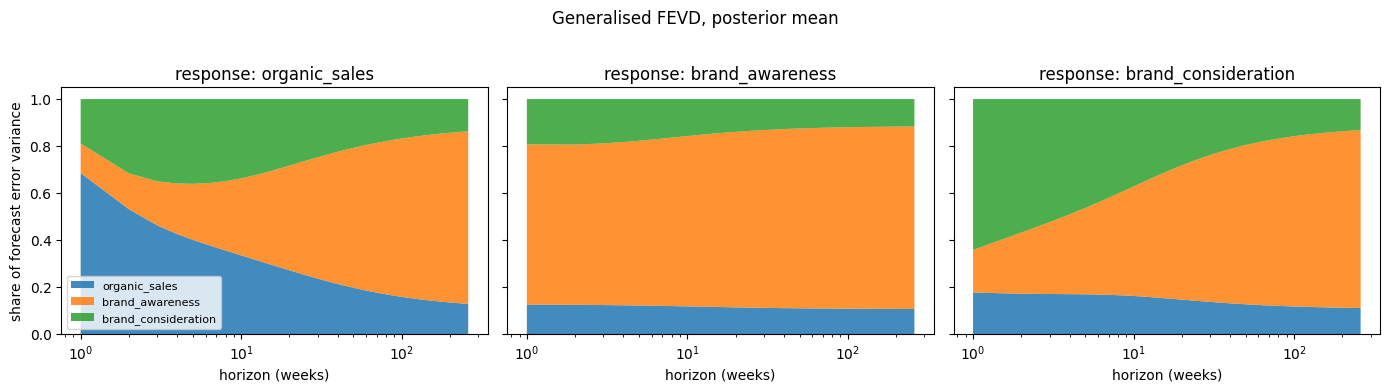

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
horizons = fevd.coords["horizon"].values
for ax, response in zip(axes, names, strict=True):
    shares = fevd_mean.sel(response_variable=response).to_pandas()
    ax.stackplot(horizons, shares.T.values, labels=shares.columns, alpha=0.85)
    ax.set_title(f"response: {response}")
    ax.set_xlabel("horizon (weeks)")
    ax.set_xscale("log")
axes[0].set_ylabel("share of forecast error variance")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Generalised FEVD, posterior mean", y=1.02)
plt.tight_layout()
plt.show()

At one week each series' own shocks dominate its forecast error. By 52 weeks awareness shocks explain most of the uncertainty in all three series.

That follows from the truth. Awareness is the only series that does not adjust, so its shocks are the only ones that last. In a cointegrated system the forecast error variance grows without bound, and at long horizons the permanent shocks account for nearly all of it.

The generalised shares stay well below 1 for awareness because the shocks are correlated: part of the permanent shock shows up in every series' innovation. A Cholesky ordering with awareness first gives that common part to awareness.

In [9]:
order = ["brand_awareness", "brand_consideration", "organic_sales"]
chol = model.fevd(steps=1040, method="cholesky", order=order).mean(("chain", "draw"))
aware = "brand_awareness"
table = pd.DataFrame(
    {
        "girf, 260 weeks": fevd_mean.sel(horizon=260, shock_variable=aware).to_pandas(),
        "cholesky, 260 weeks": chol.sel(horizon=260, shock_variable=aware).to_pandas(),
        "cholesky, 1040 weeks": chol.sel(horizon=1040, shock_variable=aware).to_pandas(),
    }
)
print("Share of forecast error variance due to awareness shocks")
print(table.round(3))

Share of forecast error variance due to awareness shocks
                     girf, 260 weeks  cholesky, 260 weeks  \
response_variable                                           
organic_sales                  0.734                0.917   
brand_awareness                0.776                0.937   
brand_consideration            0.757                0.929   

                     cholesky, 1040 weeks  
response_variable                          
organic_sales                       0.931  
brand_awareness                     0.936  
brand_consideration                 0.934  


With awareness first its share rises to about 0.93 and stays there. It stops short of 1 because the posterior row of $\alpha$ for awareness is near zero but not exactly zero. The other shocks keep a small permanent effect.

## 4. What this unlocks

The package now reports what drives what from both ends:

| Before the fit | After the fit |
|---|---|
| `granger_pretest`: F tests on a levels VAR | `granger_causality`: posterior evidence on $\Gamma$, $\Pi$, $\alpha$ and $B$ |
| same-period residual correlation | `fevd`: shares of forecast uncertainty |

The practitioner guide (§8) runs both on the brand data and reads them for a marketing audience. `docs/granger_pretest.md` measures how often the pretest finds each true link across 200 seeds.